# Task 4.0 - Neural Networks
Goal: Building a Neural Network classifier from scratch to classify images of dinosaur teeth into their respective classes.     
Deadline: 21st January

In [121]:
import os
import cv2
import numpy as np
import matplotlib.pyplot as plt

### Dataset Structure and Loading

The dataset is organized into two main folders: `Train` and `Test`.  
Each contains five subfolders corresponding to the five dinosaur classes.

Images are:
- Loaded from disk using Python's `os` module
- Converted to grayscale
- Resized to a fixed resolution
- Flattened into a 1D vector

Flattening allows the image to be treated as a numerical feature vector suitable for a fully connected neural network.

In [122]:
def load_images_from_folder(base_path, class_to_label, img_size=(64, 64)):
    X = []
    Y = []

    for class_name, label in class_to_label.items():
        class_folder = os.path.join(base_path, class_name)

        for file in os.listdir(class_folder):
            img_path = os.path.join(class_folder, file)

            # Read image in grayscale
            img = cv2.imread(img_path, cv2.IMREAD_GRAYSCALE)

            if img is None:
                continue  # skip corrupted files

            # Resize
            img = cv2.resize(img, img_size)

            # Flatten
            img = img.flatten()

            X.append(img)
            Y.append(label)

    return np.array(X), np.array(Y)


In [123]:
class_to_label = {
    'Jade': 0,
    'James': 1,
    'Jane': 2,
    'Joel': 3,
    'Jovi': 4
}

X_train, Y_train = load_images_from_folder("data/Train", class_to_label)
X_test, Y_test = load_images_from_folder("data/Test", class_to_label)


In [124]:
print("Train X shape:", X_train.shape)
print("Train Y shape:", Y_train.shape)
print("Test X shape:", X_test.shape)
print("Test Y shape:", Y_test.shape)
print("Unique labels:", np.unique(Y_train))

Train X shape: (4000, 4096)
Train Y shape: (4000,)
Test X shape: (1000, 4096)
Test Y shape: (1000,)
Unique labels: [0 1 2 3 4]


### Feature Representation and Preprocessing

Each image is flattened into a vector of length 4096 and normalized to ensure numerical stability.

Preprocessing steps include:
- Scaling pixel values
- Converting labels into integer class indices
- One-hot encoding labels for multi-class classification

One-hot encoding is required because the network outputs a probability distribution over all classes.

In [125]:
#Normalizing pixel values to prevent exploding gradients
X_train = X_train / 255.0
X_test = X_test / 255.0

In [126]:
def one_hot_encode(y, num_classes):
    one_hot = np.zeros((len(y), num_classes))
    for i, label in enumerate(y):
        one_hot[i, label] = 1
    return one_hot

In [127]:
num_classes = 5

Y_train_oh = one_hot_encode(Y_train, num_classes)
Y_test_oh = one_hot_encode(Y_test, num_classes)

print(Y_train_oh.shape)    # (4000, 5)
print(Y_test_oh.shape)     # (1000, 5)

(4000, 5)
(1000, 5)


### Neural Network Architecture

The neural network consists of:

- Input Layer: 4096 neurons (flattened image)
- Hidden Layer: 256 neurons with ReLU activation
- Output Layer: 5 neurons with Softmax activation

ReLU introduces non-linearity and helps avoid vanishing gradients,  
while Softmax converts raw scores into class probabilities.


In [128]:
def relu(Z):
    return np.maximum(0, Z)

In [129]:
def softmax(Z):
    #Z is shifted since is Z is very big, exp explodes(ex. e^100=inf),z-max(z) keeps probabilities same,numbers safer
    Z_shifted = Z - np.max(Z, axis=1, keepdims=True) #keepdims=true -> (3,) becomes (3,1)
    exp_Z = np.exp(Z_shifted)
    return exp_Z / np.sum(exp_Z, axis=1, keepdims=True)

### Forward Propagation

The forward pass consists of:

1. Linear transformation at the hidden layer
2. ReLU activation
3. Linear transformation at the output layer
4. Softmax activation

Numerical stability is ensured by subtracting the maximum logit before applying Softmax.


In [130]:
def forward(X):
    # Layer 1
    Z1 = np.dot(X, W1) + b1      # (N, 256)
    A1 = relu(Z1)                # (N, 256)

    # Layer 2
    Z2 = np.dot(A1, W2) + b2     # (N, 5)
    A2 = softmax(Z2)             # (N, 5)

    cache = (Z1, A1, Z2, A2)
    return A2, cache

### Cross-Entropy Loss

Cross-entropy loss measures the difference between the predicted probability distribution and the true distribution.

It strongly penalizes confident but incorrect predictions and works naturally with Softmax outputs.

In [131]:
def cross_entropy_loss(Y_true, Y_pred):
    m = Y_true.shape[0]
    eps = 1e-9

    data_loss = -np.sum(Y_true * np.log(Y_pred + eps)) / m

    l2_loss = (lambda_reg / (2 * m)) * (
        np.sum(W1**2) + np.sum(W2**2)
    )

    return data_loss + l2_loss


### Backpropagation

Backpropagation computes gradients of the loss with respect to all parameters using the chain rule.

Gradients are calculated for:
- Output layer weights and biases
- Hidden layer weights and biases

ReLU derivatives ensure gradients flow only through active neurons.


In [132]:
def backward(X, Y, cache):
    Z1, A1, Z2, Y_pred = cache
    m = X.shape[0]

    dZ2 = Y_pred - Y
    dW2 = (1/m) * A1.T @ dZ2 + (lambda_reg / m) * W2
    db2 = (1/m) * np.sum(dZ2, axis=0, keepdims=True)

    dA1 = dZ2 @ W2.T
    dZ1 = dA1 * (Z1 > 0)   # ReLU derivative

    dW1 = (1/m) * X.T @ dZ1 + (lambda_reg / m) * W1
    db1 = (1/m) * np.sum(dZ1, axis=0, keepdims=True)

    return dW1, db1, dW2, db2

In [133]:
def update_params(lr, dW1, db1, dW2, db2):
    global W1, b1, W2, b2
    W1 -= lr * dW1
    b1 -= lr * db1
    W2 -= lr * dW2
    b2 -= lr * db2

In [134]:
def accuracy(Y_true_oh, Y_pred):
    y_true = np.argmax(Y_true_oh, axis=1)
    y_pred = np.argmax(Y_pred, axis=1)
    return np.mean(y_true == y_pred)

### Parameter Initialization

Weights are initialized with small random values, while biases are initialized to zero.

Proper initialization is important to:
- Break symmetry
- Enable effective gradient flow
- Avoid exploding or vanishing activations

Both standard initialization and He initialization were tested.

In [135]:
def init_params(input_dim, hidden_dim, output_dim):
    np.random.seed(42)

    W1 = np.random.randn(input_dim, hidden_dim) * 0.01
    b1 = np.zeros((1,hidden_dim))

    W2 = np.random.randn(hidden_dim, output_dim) * 0.01
    b2 = np.zeros((1,output_dim))

    return W1, b1, W2, b2

In [136]:
perm = np.random.permutation(len(X_train))
X_train = X_train[perm]
Y_train_oh = Y_train_oh[perm]

X_train_split = X_train[:3500]
Y_train_split = Y_train_oh[:3500]

X_val = X_train[3500:]
Y_val_oh = Y_train_oh[3500:]

input_dim = X_train.shape[1]   # 4096
hidden_dim = 256    
output_dim = 5

W1, b1, W2, b2 = init_params(input_dim, hidden_dim, output_dim)

print(W1.shape, b1.shape)   #(4096, 256) (256,)
print(W2.shape, b2.shape)   #(256, 5) (5,)

(4096, 256) (1, 256)
(256, 5) (1, 5)


### Training Loop and Metrics

The model is trained using full-batch gradient descent.

Metrics tracked during training:
- Training accuracy
- Validation accuracy
- Cross-entropy loss

A validation split is created by shuffling the dataset to ensure class balance.

In [137]:
lr = 0.09
lambda_reg = 1e-4
epochs = 50
train_losses = []
val_losses = []
train_accuracies = []
val_accuracies = []

for epoch in range(epochs):
    # Forward pass (train)
    Y_pred, cache = forward(X_train)
    train_loss = cross_entropy_loss(Y_train_oh, Y_pred)
    train_acc = accuracy(Y_train_oh, Y_pred)

    # Forward pass (validation)
    Y_val_pred, _ = forward(X_val)
    val_loss = cross_entropy_loss(Y_val_oh, Y_val_pred)
    val_acc = accuracy(Y_val_oh, Y_val_pred)

    # Store metrics
    train_losses.append(train_loss)
    val_losses.append(val_loss)
    train_accuracies.append(train_acc)
    val_accuracies.append(val_acc)

    # Backprop + update (TRAIN ONLY)
    dW1, db1, dW2, db2 = backward(X_train, Y_train_oh, cache)
    update_params(lr, dW1, db1, dW2, db2)
    
    if epoch % 5 == 0 or epoch == epochs-1:
        print(f"Epoch {epoch}, Loss: {train_loss:.4f}, Accuracy: {train_acc:.4f}, Validation Accuracy: {val_acc:.4f}")


Epoch 0, Loss: 1.6079, Accuracy: 0.1903, Validation Accuracy: 0.2200
Epoch 5, Loss: 1.5486, Accuracy: 0.2000, Validation Accuracy: 0.2620
Epoch 10, Loss: 1.4698, Accuracy: 0.2077, Validation Accuracy: 0.2660
Epoch 15, Loss: 1.3448, Accuracy: 0.5095, Validation Accuracy: 0.5620
Epoch 20, Loss: 1.2035, Accuracy: 0.5490, Validation Accuracy: 0.5940
Epoch 25, Loss: 1.0802, Accuracy: 0.6600, Validation Accuracy: 0.6800
Epoch 30, Loss: 0.9721, Accuracy: 0.7392, Validation Accuracy: 0.7540
Epoch 35, Loss: 0.8743, Accuracy: 0.8075, Validation Accuracy: 0.8280
Epoch 40, Loss: 0.7863, Accuracy: 0.8525, Validation Accuracy: 0.8680
Epoch 45, Loss: 0.7085, Accuracy: 0.8818, Validation Accuracy: 0.8900
Epoch 49, Loss: 0.6536, Accuracy: 0.8918, Validation Accuracy: 0.8960


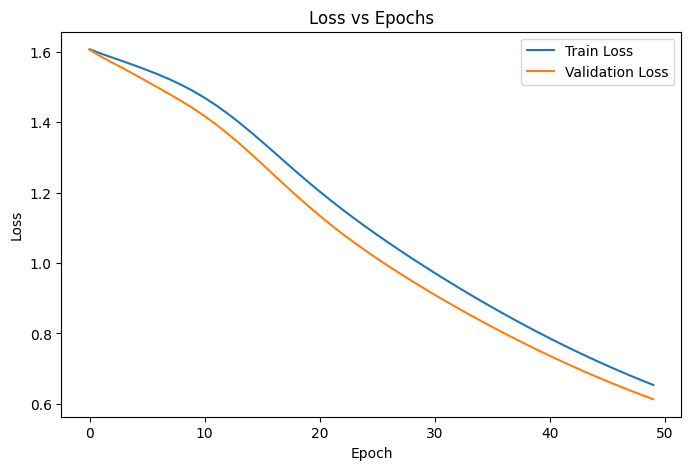

In [138]:
#Loss Curves
plt.figure(figsize=(8,5))
plt.plot(train_losses, label="Train Loss")
plt.plot(val_losses, label="Validation Loss")
plt.xlabel("Epoch")
plt.ylabel("Loss")
plt.title("Loss vs Epochs")
plt.legend()
plt.show()

### Learning Curves and Overfitting Analysis

Training and validation loss and accuracy curves were plotted.

Observations:
- Both losses decrease smoothly
- Training and validation accuracy improve together
- No divergence between curves

This indicates that the model does not significantly overfit and generalizes well.


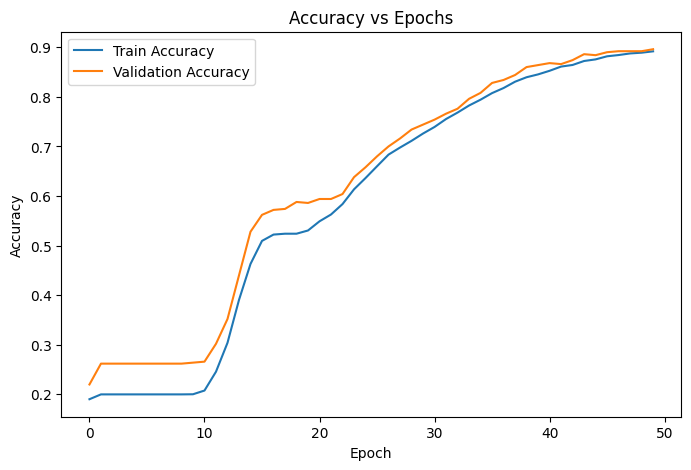

In [139]:
#Accuracy Curves
plt.figure(figsize=(8,5))
plt.plot(train_accuracies, label="Train Accuracy")
plt.plot(val_accuracies, label="Validation Accuracy")
plt.xlabel("Epoch")
plt.ylabel("Accuracy")
plt.title("Accuracy vs Epochs")
plt.legend()
plt.show()

### L2 Regularization Experiments

L2 regularization was tested with multiple values of λ.

While accuracy remained largely unchanged, L2 resulted in smoother learning curves and more stable optimization.

This suggests the baseline model was already well-regularized and not prone to overfitting.

In [140]:
Y_test_pred, _ = forward(X_test)
test_acc = accuracy(Y_test_oh, Y_test_pred)

print("Test Accuracy:", test_acc)

Test Accuracy: 0.897


## Final Results and Conclusions

The final neural network achieved:

- Training Accuracy: ~89%
- Validation Accuracy: ~89%
- Test Accuracy: ~89%

Key findings:
- Increasing hidden layer size improved performance more than regularization
- L2 regularization improved training stability but not accuracy
- Learning curves showed no signs of overfitting
- PCA or dimensionality reduction was not required due to strong feature representations

Overall, the model successfully learned meaningful patterns from high-dimensional image data using a simple, fully connected architecture implemented from scratch.